# Stories Coffee: explore the data before choosing the project

**Goal:** find a business decision supported by transaction data. Start with quality, then demand, economics, and changes around March 2. Each section explains what its chart can and cannot establish.

## Run in Google Colab
1. Open https://colab.research.google.com/ and choose **File → Upload notebook**.
2. Upload this `.ipynb`, then choose **Runtime → Run all**. Upload your transaction CSV when prompted.
3. Change the settings below to explore other dates. No API keys or paid services are needed.

Charts and tables below are already executed on the supplied file. Re-running replaces those outputs with results from your selected CSV. The original CSV is never edited, and exact duplicates are retained unless you explicitly investigate them.

**Sources:** supplied `stories_transactions(1).csv` and `EECE490 Stories Coffee Hackathon.pdf`. The UN identifies March 2, 2026 as the renewed escalation date: [UN statement, March 17](https://lebanon.un.org/en/312364-statement-un-humanitarian-coordinator-imran-riza-un-geneva-press-briefing). This establishes an external event date, not its effect on these branches. Confirm that dataset dates retain original timing before linking them to real-world events.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.constrained_layout.use':True})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

CSV_PATH = None  # Optional: '/content/stories_transactions(1).csv'
EVENT_DATE = pd.Timestamp('2026-03-02')
WINDOW_DAYS = 28  # Multiple of 7 gives equal weekday counts on both sides.
REFERENCE_BRANCH = 'Harbour'


## 1. Load and validate
One CSV row is an **item line**, not necessarily an order or a person. Count orders using distinct transaction IDs. Check required fields and accounting identities before interpreting the charts.


In [2]:
if CSV_PATH is None:
    candidates = sorted(Path('.').glob('stories_transactions*.csv'))
    candidates += sorted(Path('upload').glob('stories_transactions*.csv'))
    if len(candidates) == 1:
        CSV_PATH = candidates[0]
    else:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError('Set CSV_PATH to the CSV you want to analyze.')
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
        if len(csv_files) != 1:
            raise ValueError('Upload exactly one transaction CSV, or set CSV_PATH explicitly.')
        CSV_PATH = csv_files[0]

raw = pd.read_csv(CSV_PATH)
required = ['Transaction ID','Date','Time','Branch','Customer ID','Order Type',
            'Product','Category','Quantity','Unit Price (USD)','Discount Rate',
            'Unit Cost (USD)','Line Revenue (USD)','Line Gross Profit (USD)']
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Missing columns: {missing_columns}')
print(f'Loaded {Path(CSV_PATH).name}: {len(raw):,} item lines, {raw.shape[1]} columns.')
display(raw.head())


Loaded stories_transactions(1).csv: 51,177 item lines, 14 columns.


,Transaction ID,Date,Time,Branch,Customer ID,Order Type,Product,Category,Quantity,Unit Price (USD),Discount Rate,Unit Cost (USD),Line Revenue (USD),Line Gross Profit (USD)
0,SYN-0000001,2026-01-01,22:37:35,Harbour,C01797,Takeaway,Fresh Orange Juice,Cold Drinks,1,6.040,0.000,2.120,6.040,3.920
1,SYN-0000002,2026-01-01,17:34:07,Garden,NaN,Dine-in,Egg Sandwich,Breakfast,1,8.150,0.000,4.450,8.150,3.700
2,SYN-0000003,2026-01-01,22:45:29,Harbour,NaN,Dine-in,Brownie,Desserts,1,5.410,0.000,2.370,5.410,3.040
3,SYN-0000004,2026-01-01,21:36:38,Uptown,NaN,Dine-in,Iced Mocha,Cold Coffee,1,6.000,0.000,2.140,6.000,3.860
4,SYN-0000005,2026-01-01,12:34:01,Harbour,C01616,Dine-in,Classic Matcha,Matcha & Tea,1,6.770,0.000,2.270,6.770,4.500


In [3]:
df = raw.rename(columns={
    'Transaction ID':'transaction','Date':'date','Time':'time','Branch':'branch',
    'Customer ID':'customer','Order Type':'order_type','Product':'product',
    'Category':'category','Quantity':'quantity','Unit Price (USD)':'price',
    'Discount Rate':'discount','Unit Cost (USD)':'cost',
    'Line Revenue (USD)':'revenue','Line Gross Profit (USD)':'gross_profit'
}).copy()
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d', errors='coerce')
clock = pd.to_datetime(df['time'], format='%H:%M:%S', errors='coerce')
df['hour'] = clock.dt.hour
numeric = ['quantity','price','discount','cost','revenue','gross_profit']
for col in numeric:
    df[col] = pd.to_numeric(df[col], errors='coerce')
must_exist = ['transaction','date','hour','branch','order_type','product','category'] + numeric
bad_missing = df[must_exist].isna().sum()
if bad_missing.sum():
    display(bad_missing[bad_missing.gt(0)].rename('Missing / invalid'))
    raise ValueError('Resolve missing required values before continuing.')
if (df['quantity'] <= 0).any() or (~df['discount'].between(0,1)).any():
    raise ValueError('Returns/nonpositive quantities or invalid discounts require a separate treatment.')

rev_error = df['revenue'] - df['quantity'] * df['price'] * (1-df['discount'])
gp_error = df['gross_profit'] - (df['revenue']-df['quantity']*df['cost'])
quality = pd.Series({
    'Item lines':len(df), 'Distinct orders':df['transaction'].nunique(),
    'Products':df['product'].nunique(), 'Branches':df['branch'].nunique(),
    'Exact duplicate rows beyond first':int(raw.duplicated().sum()),
    'Revenue reconciliation errors > $0.01':int(rev_error.abs().gt(.01001).sum()),
    'Gross-profit reconciliation errors > $0.01':int(gp_error.abs().gt(.01001).sum())
}, name='Count')
display(quality.to_frame())
print('Date range:', df['date'].min().date(), 'to', df['date'].max().date())
display(raw.isna().sum().to_frame('Missing item-line values'))
print('Exact duplicate rows are retained: repeated identical items may be valid order entries.')


Date range: 2026-01-01 to 2026-06-30
Exact duplicate rows are retained: repeated identical items may be valid order entries.


,Count
Item lines,51177
Distinct orders,33887
Products,45
Branches,3
Exact duplicate rows beyond first,132
Revenue reconciliation errors > $0.01,0
Gross-profit reconciliation errors > $0.01,0


,Missing item-line values
Transaction ID,0
Date,0
Time,0
Branch,0
Customer ID,18691
Order Type,0
Product,0
Category,0
Quantity,0
Unit Price (USD),0


## 2. Create the right units of analysis
Use **item lines** for product quantities and costs, **orders** for basket value and channel share, and a **branch-day panel** for demand. A missing branch-day is filled with zero recorded orders; this does not prove that the branch was open or closed.


In [4]:
grouped = df.groupby('transaction', sort=False)
consistency = grouped[['date','time','branch','customer','order_type']].nunique(dropna=False).gt(1).sum()
display(consistency.to_frame('Orders with conflicting values'))
if consistency.sum():
    raise ValueError('Transaction IDs do not consistently identify one order; investigate grouping.')
tickets = grouped.agg(date=('date','first'), branch=('branch','first'),
    customer=('customer','first'), order_type=('order_type','first'), hour=('hour','first'),
    revenue=('revenue','sum'), gross_profit=('gross_profit','sum'),
    units=('quantity','sum'), lines=('product','size'), discount=('discount','max')).reset_index()
tickets['takeaway'] = tickets['order_type'].eq('Takeaway')
tickets['discounted'] = tickets['discount'].gt(0)
branches = sorted(df['branch'].unique())
dates = pd.date_range(df['date'].min(),df['date'].max(),freq='D')
grid = pd.MultiIndex.from_product([dates,branches],names=['date','branch'])
daily = tickets.groupby(['date','branch']).agg(orders=('transaction','size'),
    revenue=('revenue','sum'), gross_profit=('gross_profit','sum')).reindex(grid,fill_value=0).reset_index()
daily['weekday'] = daily['date'].dt.dayofweek
print(f'{len(tickets):,} orders; customer ID missing on {tickets.customer.isna().mean():.1%} of orders.')
print('Recorded gross profit excludes expenses not represented by unit cost, such as rent and labor.')


33,887 orders; customer ID missing on 36.5% of orders.
Recorded gross profit excludes expenses not represented by unit cost, such as rent and labor.


,Orders with conflicting values
date,0
time,0
branch,0
customer,0
order_type,0


## 3. Is demand changing over time?
**Question:** is there an abrupt change, an existing growth trend, or simply a recurring weekday pattern? The trailing seven-day average uses current and past days. The event marker is context; it is not evidence of causation.


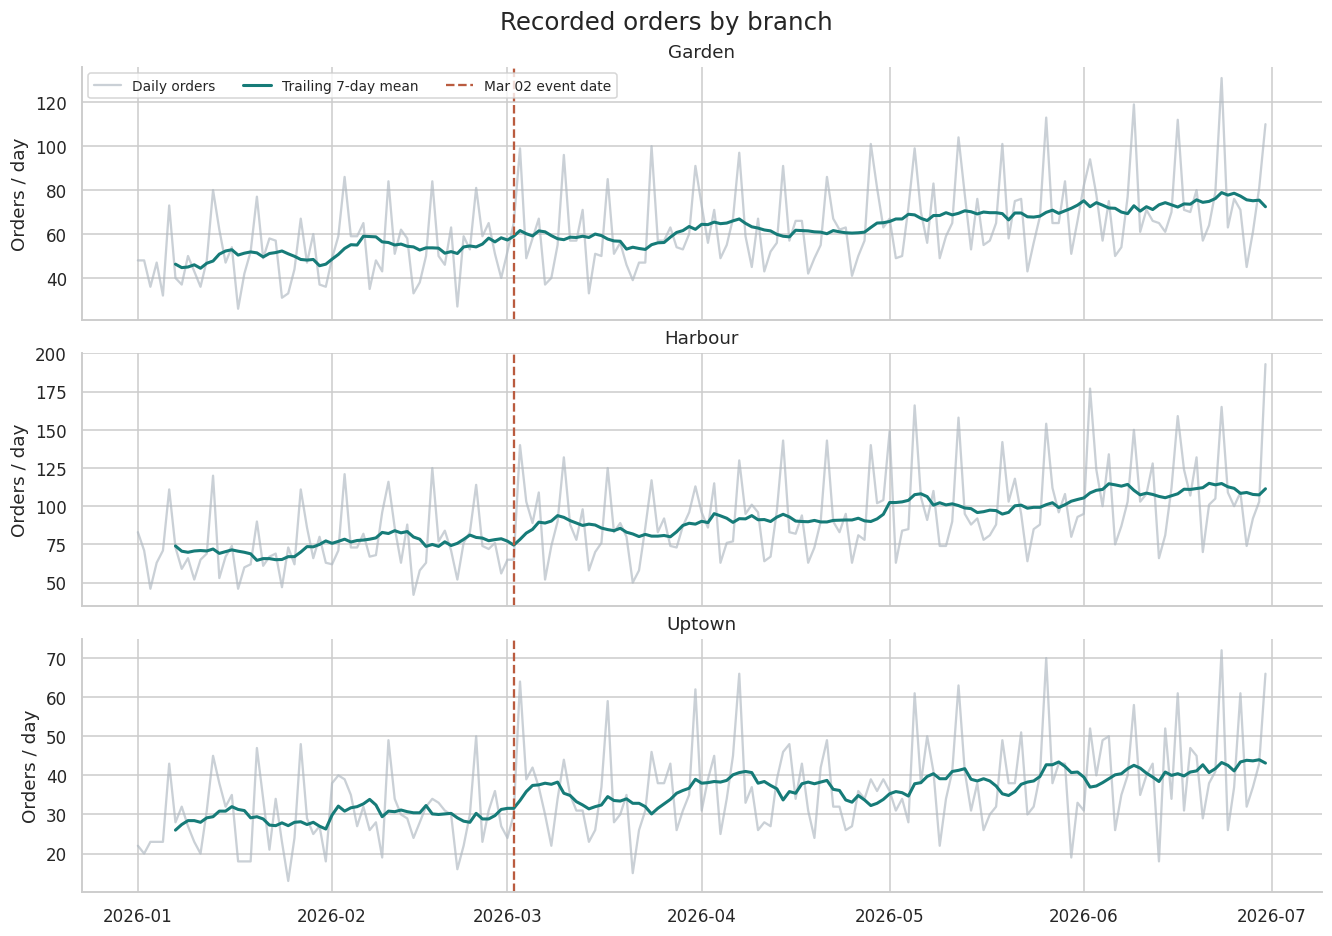

In [5]:
fig, axes = plt.subplots(len(branches),1,figsize=(12,2.8*len(branches)),sharex=True,squeeze=False)
for ax, branch in zip(axes.flat,branches):
    x = daily[daily.branch.eq(branch)].set_index('date')
    ax.plot(x.index,x.orders,color='#aeb8c1',alpha=.65,label='Daily orders')
    ax.plot(x.index,x.orders.rolling(7,min_periods=7).mean(),color='#167b78',lw=2,label='Trailing 7-day mean')
    ax.axvline(EVENT_DATE,color='#ba5b3f',ls='--',label=f'{EVENT_DATE:%b %d} event date')
    ax.set(title=branch,ylabel='Orders / day')
axes[0,0].legend(ncol=3,loc='upper left',fontsize=9)
fig.suptitle('Recorded orders by branch',fontsize=16)
plt.show()


## 4. When do customers buy?
**Question:** which weekday-hour combinations account for demand? Counts are divided by the number of calendar occurrences of each weekday, rather than comparing raw totals. Sales timestamps do not measure queues, service capacity, or safe operating hours.


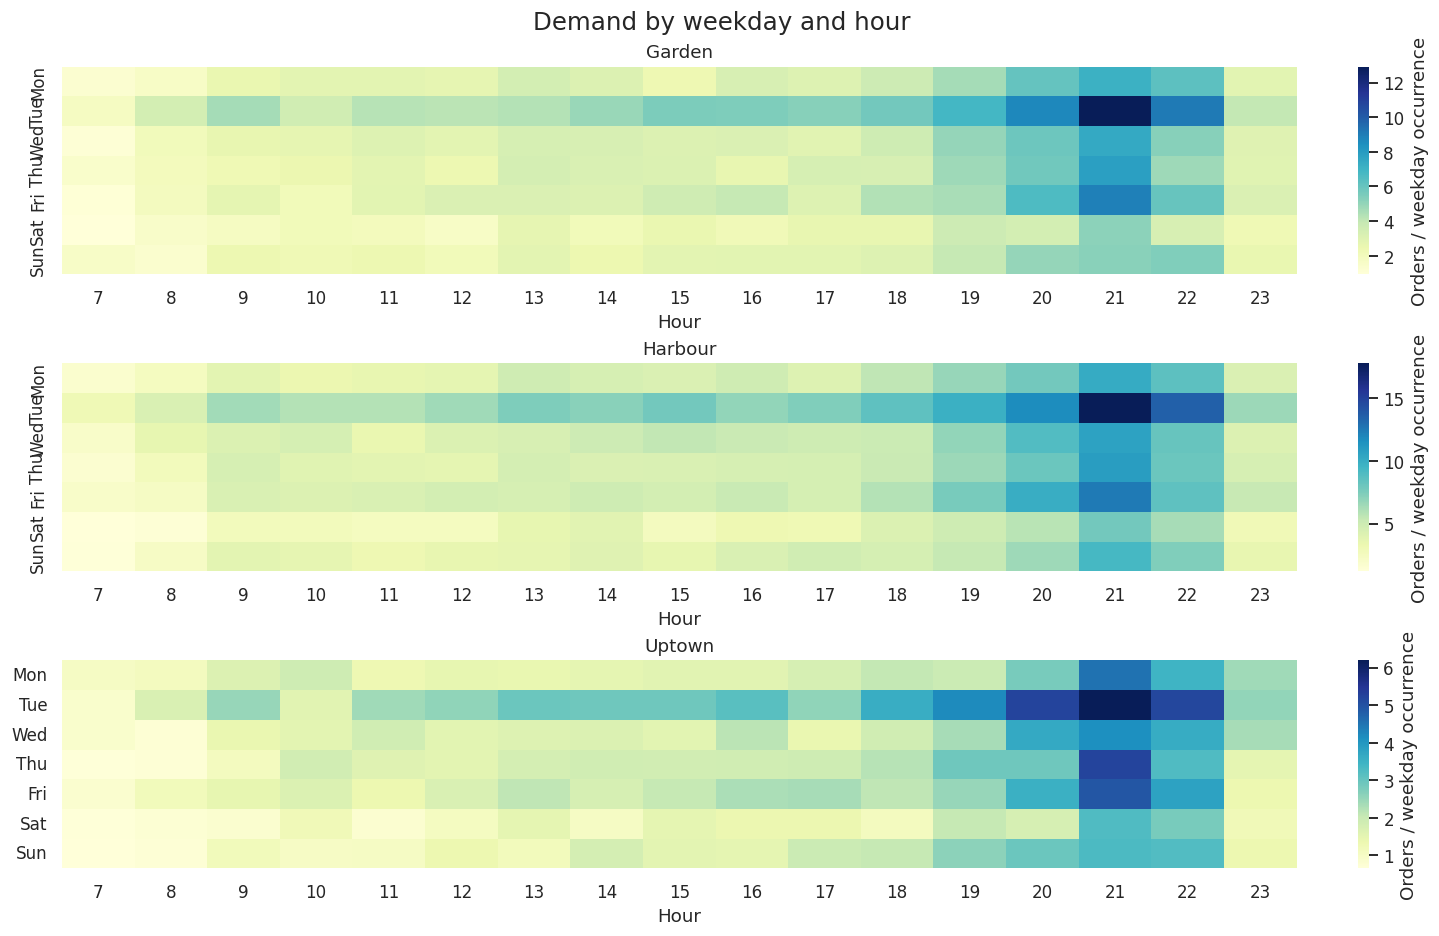

In [6]:
weekday_names = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
weekday_days = pd.Series(dates.dayofweek).value_counts().reindex(range(7),fill_value=0)
hours = range(int(tickets.hour.min()),int(tickets.hour.max())+1)
fig,axes = plt.subplots(len(branches),1,figsize=(13,2.8*len(branches)),squeeze=False)
for ax,branch in zip(axes.flat,branches):
    x=tickets[tickets.branch.eq(branch)].copy()
    x['weekday']=x.date.dt.dayofweek
    h=pd.crosstab(x.weekday,x.hour).reindex(index=range(7),columns=hours,fill_value=0)
    h=h.div(weekday_days.replace(0,np.nan),axis=0)
    h.index=weekday_names
    sns.heatmap(h,ax=ax,cmap='YlGnBu',cbar_kws={'label':'Orders / weekday occurrence'})
    ax.set(title=branch,xlabel='Hour',ylabel='')
fig.suptitle('Demand by weekday and hour',fontsize=16)
plt.show()


## 5. Where does gross profit differ?
**Question:** does a lower-profit branch have fewer orders, smaller baskets, or weaker product economics? Margin is total gross profit / total revenue, never a simple average of line margins.


,orders,revenue,gross_profit,units,revenue_per_order,gp_per_order,gross_margin_pct
branch,,,,,,,
Garden,11163,"99,748.550","46,794.490",17833,8.940,4.190,46.910
Harbour,16334,"150,483.580","97,753.940",26093,9.210,5.980,64.960
Uptown,6390,"55,693.010","34,882.060",10161,8.720,5.460,62.630


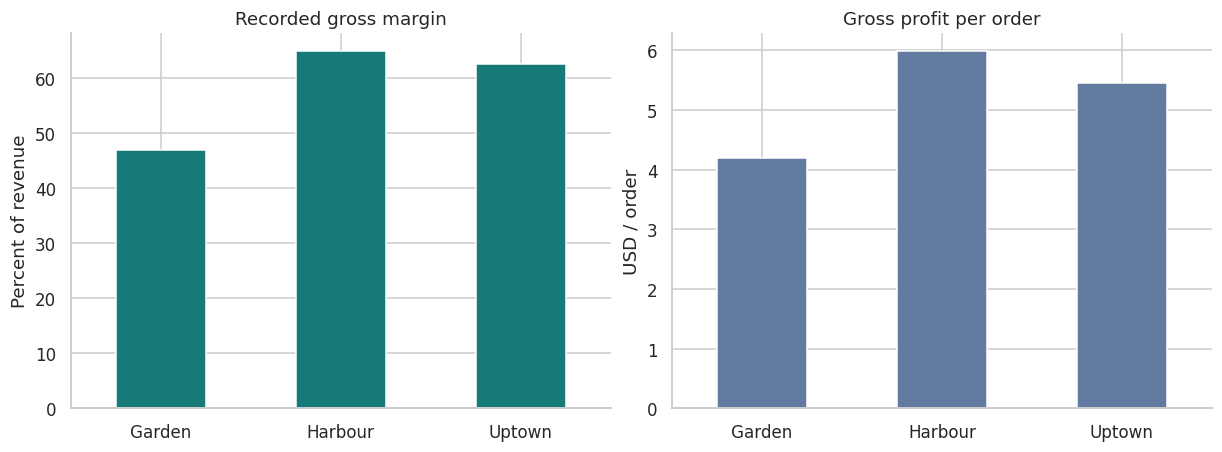

In [7]:
b=tickets.groupby('branch').agg(orders=('transaction','size'),revenue=('revenue','sum'),
    gross_profit=('gross_profit','sum'),units=('units','sum'))
b['revenue_per_order']=b.revenue/b.orders
b['gp_per_order']=b.gross_profit/b.orders
b['gross_margin_pct']=100*b.gross_profit/b.revenue
display(b.round(2))
fig,axes=plt.subplots(1,2,figsize=(11,4))
b.gross_margin_pct.plot.bar(ax=axes[0],color='#167b78',rot=0)
axes[0].set(title='Recorded gross margin',ylabel='Percent of revenue',xlabel='')
b.gp_per_order.plot.bar(ax=axes[1],color='#637aa1',rot=0)
axes[1].set(title='Gross profit per order',ylabel='USD / order',xlabel='')
plt.show()


## 6. Which products contribute value?
Quantity measures popularity; gross profit per unit measures recorded contribution per unit. High total profit can come from high volume, high unit contribution, or both. Product-removal decisions also require substitution, preparation and inventory information.


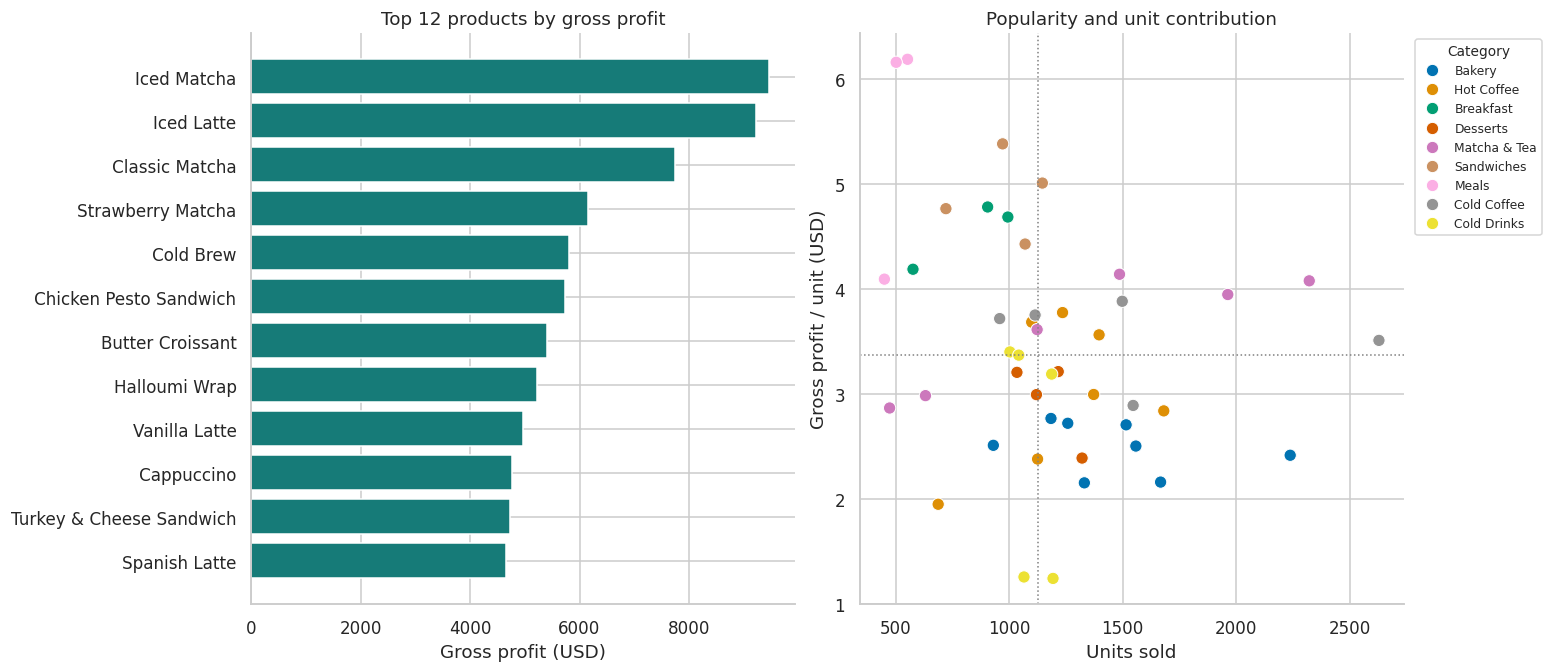

,product,category,units,revenue,gross_profit,gp_per_unit,gross_margin_pct
29,Iced Matcha,Matcha & Tea,2322,"16,074.450","9,462.450",4.080,58.870
28,Iced Latte,Cold Coffee,2629,"14,131.400","9,222.290",3.510,65.260
16,Classic Matcha,Matcha & Tea,1963,"12,804.910","7,743.310",3.940,60.470
40,Strawberry Matcha,Matcha & Tea,1486,"11,494.830","6,148.280",4.140,53.490
18,Cold Brew,Cold Coffee,1498,"7,767.710","5,812.730",3.880,74.830
11,Chicken Pesto Sandwich,Sandwiches,1146,"12,383.980","5,736.910",5.010,46.330
6,Butter Croissant,Bakery,2238,"8,270.860","5,402.610",2.410,65.320
26,Halloumi Wrap,Sandwiches,971,"9,709.220","5,223.390",5.380,53.800
44,Vanilla Latte,Hot Coffee,1396,"7,695.190","4,970.750",3.560,64.600
7,Cappuccino,Hot Coffee,1681,"6,886.260","4,768.340",2.840,69.240


In [8]:
products=df.groupby(['product','category']).agg(units=('quantity','sum'),
    revenue=('revenue','sum'),gross_profit=('gross_profit','sum')).reset_index()
products['gp_per_unit']=products.gross_profit/products.units
products['gross_margin_pct']=100*products.gross_profit/products.revenue
top=products.nlargest(12,'gross_profit').sort_values('gross_profit')
fig,axes=plt.subplots(1,2,figsize=(14,6))
axes[0].barh(top['product'],top.gross_profit,color='#167b78')
axes[0].set(title='Top 12 products by gross profit',xlabel='Gross profit (USD)')
sns.scatterplot(data=products,x='units',y='gp_per_unit',hue='category',s=65,ax=axes[1])
axes[1].axvline(products.units.median(),color='gray',ls=':',lw=1)
axes[1].axhline(products.gp_per_unit.median(),color='gray',ls=':',lw=1)
axes[1].set(title='Popularity and unit contribution',xlabel='Units sold',ylabel='Gross profit / unit (USD)')
axes[1].legend(title='Category',fontsize=8,title_fontsize=9,loc='upper left',bbox_to_anchor=(1.01,1))
plt.show()
display(products.nlargest(10,'gross_profit').round(2))


## 7. Compare identical products across branches
**Question:** are branch margin differences partly explained by recorded prices or costs for the same product? Ratios below summarize products, not customer demand. Similar ratios across almost every product may indicate a systematic cost allocation or pricing rule; they do not prove procurement inefficiency.


Branch-product combinations with more than one recorded value:


,Combinations
price,0
cost,0


,branch,metric,median_ratio,products_compared
0,Garden,price,0.953,45
1,Harbour,price,1.000,45
2,Uptown,price,0.914,45
3,Garden,cost,1.430,45
4,Harbour,cost,1.000,45
5,Uptown,cost,0.960,45


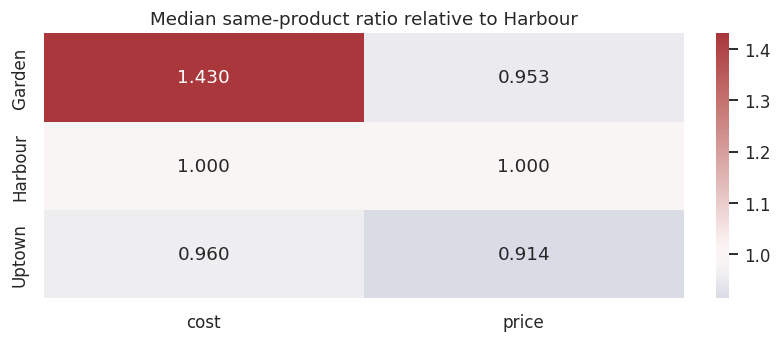

In [9]:
variation=df.groupby(['branch','product'])[['price','cost']].nunique()
print('Branch-product combinations with more than one recorded value:')
display(variation.gt(1).sum().to_frame('Combinations'))
unit=df.groupby(['product','branch']).agg(price=('price','median'),cost=('cost','median'))
reference=REFERENCE_BRANCH if REFERENCE_BRANCH in branches else branches[0]
ratio_rows=[]
for metric in ['price','cost']:
    wide=unit[metric].unstack('branch')
    ratios=wide.div(wide[reference].replace(0,np.nan),axis=0)
    for branch in branches:
        x=ratios[branch].dropna()
        ratio_rows.append({'branch':branch,'metric':metric,'median_ratio':x.median(),'products_compared':len(x)})
ratios_summary=pd.DataFrame(ratio_rows)
display(ratios_summary)
fig,ax=plt.subplots(figsize=(7,3))
sns.heatmap(ratios_summary.pivot(index='branch',columns='metric',values='median_ratio'),
            annot=True,fmt='.3f',center=1,cmap='vlag',ax=ax)
ax.set(title=f'Median same-product ratio relative to {reference}',xlabel='',ylabel='')
plt.show()


## 8. A balanced before/after comparison
Use equal windows around March 2. With 28 days on each side, weekday counts match. This removes one simple imbalance, but does not remove growth, seasonality, promotion changes, selection, or other simultaneous events. Absence of a customer ID is also not absence of a customer.


Before: 2026-02-02 to 2026-03-01
After:  2026-03-02 to 2026-03-29
Bars are descriptive means; they do not estimate a causal war effect.


,orders_per_day,revenue_per_order,gp_per_day,takeaway_pct,discounted_order_pct,customer_id_coverage_pct
period,,,,,,
Before,164.680,9.020,870.300,40.950,8.280,64.260
After,179.640,9.010,949.430,40.580,11.870,63.380


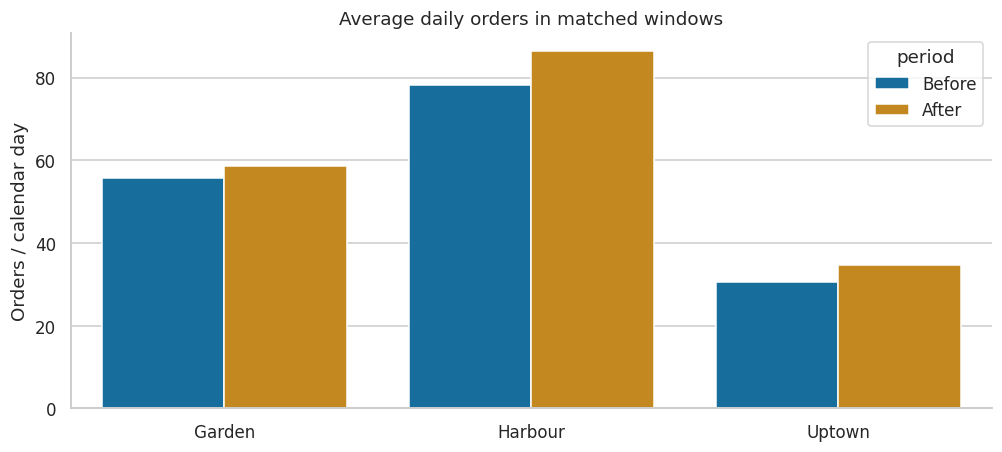

In [10]:
pre_start=EVENT_DATE-pd.Timedelta(days=WINDOW_DAYS)
post_end=EVENT_DATE+pd.Timedelta(days=WINDOW_DAYS-1)
if pre_start < dates.min() or post_end > dates.max():
    raise ValueError('Choose an event date/window fully covered by the data.')
print('Before:',pre_start.date(),'to',(EVENT_DATE-pd.Timedelta(days=1)).date())
print('After: ',EVENT_DATE.date(),'to',post_end.date())
event_tickets=tickets[tickets.date.between(pre_start,post_end)].copy()
event_tickets['period']=np.where(event_tickets.date.lt(EVENT_DATE),'Before','After')
summary=[]
for period in ['Before','After']:
    x=event_tickets[event_tickets.period.eq(period)]
    summary.append({'period':period,'orders_per_day':len(x)/WINDOW_DAYS,
      'revenue_per_order':x.revenue.mean(),'gp_per_day':x.gross_profit.sum()/WINDOW_DAYS,
      'takeaway_pct':100*x.takeaway.mean(),'discounted_order_pct':100*x.discounted.mean(),
      'customer_id_coverage_pct':100*x.customer.notna().mean()})
event_summary=pd.DataFrame(summary).set_index('period')
display(event_summary.round(2))
event_daily=daily[daily.date.between(pre_start,post_end)].copy()
event_daily['period']=np.where(event_daily.date.lt(EVENT_DATE),'Before','After')
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(data=event_daily,x='branch',y='orders',hue='period',hue_order=['Before','After'],errorbar=None,ax=ax)
ax.set(title='Average daily orders in matched windows',ylabel='Orders / calendar day',xlabel='')
plt.show()
print('Bars are descriptive means; they do not estimate a causal war effect.')


## 9. Did demand shift to different hours or categories?
Shares help distinguish redistribution from overall growth. A percentage-point difference is not a percentage change. Explore changes as hypotheses; do not select only the biggest differences and present them as confirmed effects.


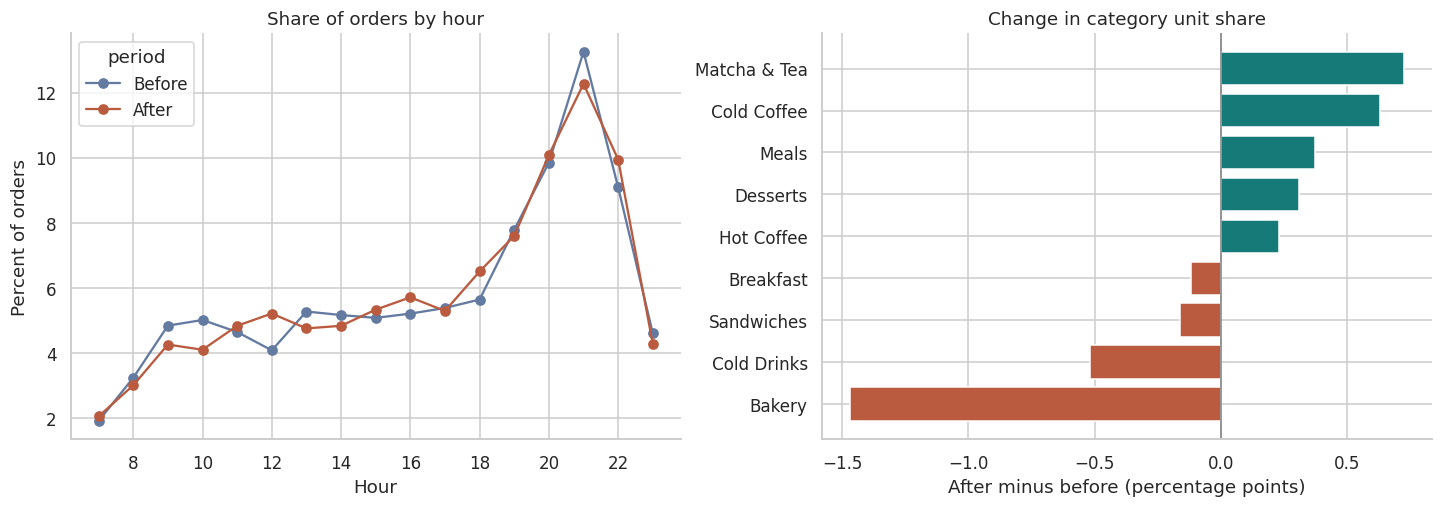

period,Before,After,change_pp
category,,,
Bakery,22.290,20.820,-1.470
Breakfast,4.760,4.640,-0.120
Cold Coffee,13.480,14.120,0.630
Cold Drinks,10.870,10.350,-0.520
Desserts,8.630,8.940,0.310
Hot Coffee,15.670,15.900,0.230
Matcha & Tea,14.610,15.330,0.730
Meals,2.430,2.810,0.370
Sandwiches,7.250,7.090,-0.160


In [11]:
hour_counts=pd.crosstab(event_tickets.hour,event_tickets.period).reindex(columns=['Before','After'],fill_value=0)
hour_share=100*hour_counts.div(hour_counts.sum(),axis=1)
event_lines=df[df.date.between(pre_start,post_end)].copy()
event_lines['period']=np.where(event_lines.date.lt(EVENT_DATE),'Before','After')
category_counts=event_lines.groupby(['category','period']).quantity.sum().unstack(fill_value=0).reindex(columns=['Before','After'])
category_share=100*category_counts.div(category_counts.sum(),axis=1)
category_shift=(category_share.After-category_share.Before).sort_values()
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
hour_share.plot(ax=axes[0],marker='o',color=['#637aa1','#ba5b3f'])
axes[0].set(title='Share of orders by hour',xlabel='Hour',ylabel='Percent of orders')
axes[1].barh(category_shift.index,category_shift,color=np.where(category_shift>=0,'#167b78','#ba5b3f'))
axes[1].axvline(0,color='gray',lw=1)
axes[1].set(title='Change in category unit share',xlabel='After minus before (percentage points)')
plt.show()
display(category_share.assign(change_pp=category_share.After-category_share.Before).round(2))


## 10. Check promotions and alternative cutoffs
If similar changes appear around many dates, a March 2 comparison may reflect a broad trend. Alternative-date comparisons below are descriptive sensitivity checks, not formal placebo tests or independent experiments. They use overlapping windows.


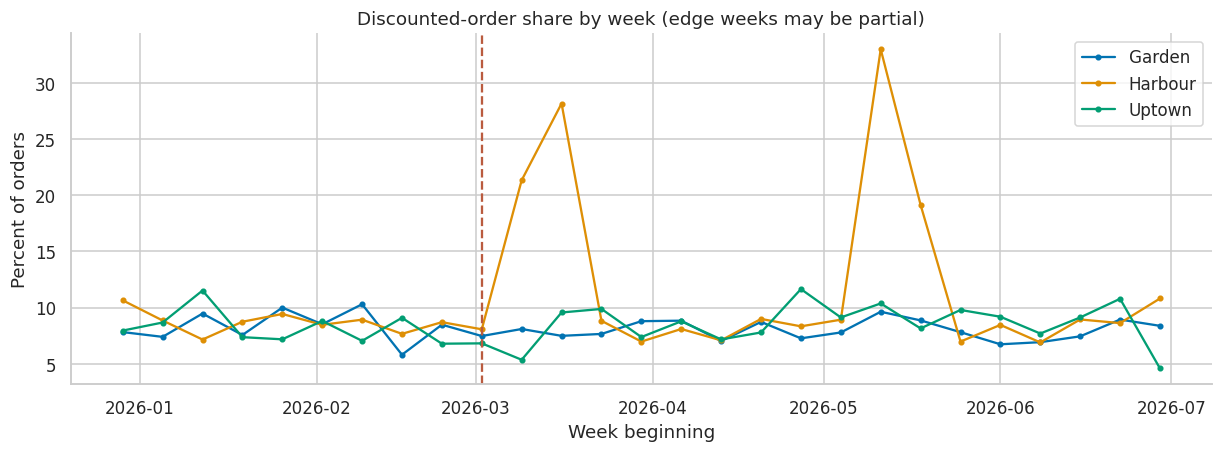

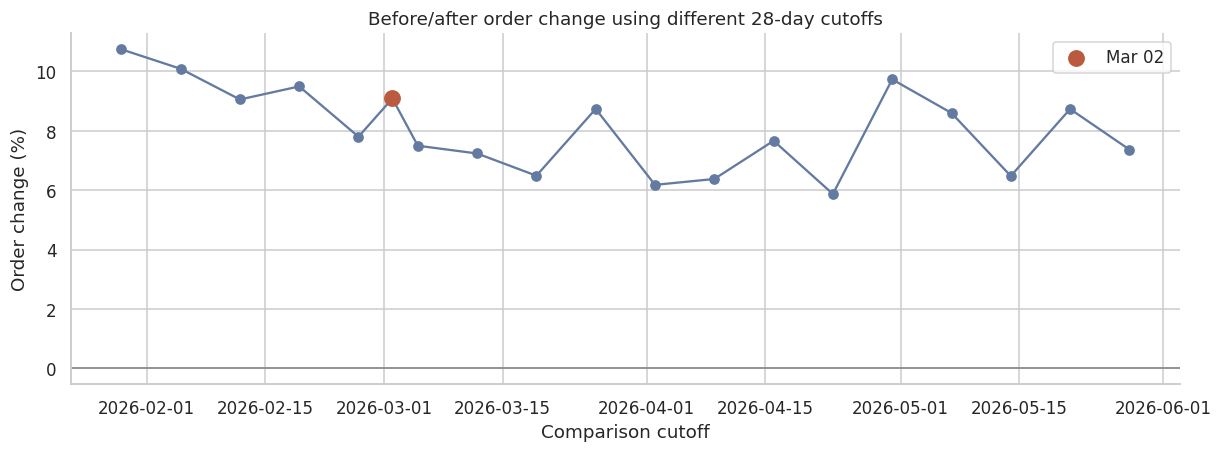

In [12]:
weekly=tickets.assign(week=tickets.date.dt.to_period('W-SUN').dt.start_time).groupby(['week','branch']).agg(
    orders=('transaction','size'),discounted_share=('discounted','mean')).reset_index()
fig,ax=plt.subplots(figsize=(11,4))
for branch in branches:
    x=weekly[weekly.branch.eq(branch)]
    ax.plot(x.week,100*x.discounted_share,marker='.',label=branch)
ax.axvline(EVENT_DATE,color='#ba5b3f',ls='--')
ax.set(title='Discounted-order share by week (edge weeks may be partial)',ylabel='Percent of orders',xlabel='Week beginning')
ax.legend()
plt.show()

cutoffs=pd.date_range(dates.min()+pd.Timedelta(days=WINDOW_DAYS),
                      dates.max()-pd.Timedelta(days=WINDOW_DAYS-1),freq='7D')
cutoffs=cutoffs.union(pd.DatetimeIndex([EVENT_DATE])).sort_values()
changes=[]
for cutoff in cutoffs:
    a=tickets[tickets.date.between(cutoff-pd.Timedelta(days=WINDOW_DAYS),cutoff-pd.Timedelta(days=1))]
    b_=tickets[tickets.date.between(cutoff,cutoff+pd.Timedelta(days=WINDOW_DAYS-1))]
    changes.append({'cutoff':cutoff,'order_change_pct':100*(len(b_)/len(a)-1) if len(a) else np.nan})
sensitivity=pd.DataFrame(changes)
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(sensitivity.cutoff,sensitivity.order_change_pct,marker='o',color='#637aa1')
point=sensitivity[sensitivity.cutoff.eq(EVENT_DATE)]
ax.scatter(point.cutoff,point.order_change_pct,s=100,color='#ba5b3f',zorder=4,label=f'{EVENT_DATE:%b %d}')
ax.axhline(0,color='gray',lw=1)
ax.set(title=f'Before/after order change using different {WINDOW_DAYS}-day cutoffs',
       xlabel='Comparison cutoff',ylabel='Order change (%)')
ax.legend()
plt.show()


## 11. How much do exact duplicates matter?
Do not silently drop them: identical lines can represent two separate identical items. This comparison quantifies sensitivity while preserving both interpretations. Resolving which interpretation is correct requires source-system knowledge.


In [13]:
keep_first=~raw.duplicated()
dup_summary=pd.DataFrame([
    {'interpretation':'Retain all lines','lines':len(df),'revenue':df.revenue.sum(),'gross_profit':df.gross_profit.sum()},
    {'interpretation':'Exclude exact repeats (sensitivity only)','lines':int(keep_first.sum()),
     'revenue':df.loc[keep_first,'revenue'].sum(),'gross_profit':df.loc[keep_first,'gross_profit'].sum()}
]).set_index('interpretation')
display(dup_summary.round(2))


,lines,revenue,gross_profit
interpretation,,,
Retain all lines,51177,"305,925.140","179,430.490"
Exclude exact repeats (sensitivity only),51045,"305,183.710","178,994.280"


## 12. Write findings before building a model
For every useful chart, complete this evidence record:

| Field | Your answer |
|---|---|
| Observation | What changed, in what population and date range? |
| Alternative explanations | Which other causes fit the pattern? |
| Decision | What could Stories actually change? |
| Missing information | What cannot be measured from transaction sales? |
| Value scenario | What benefit follows under explicitly stated assumptions? |
| Validation | What comparison, holdout, or small pilot would challenge the idea? |

### Suggested next investigations
- **Preparation and purchasing:** compare a previous-weekday baseline against a recent-demand policy. Replay decisions chronologically. Waste and unmet demand require assumptions because inventory, spoilage and stockouts are absent.
- **Margin audit:** compare identical products across branches and rank the recorded cost gaps. Validate cost definitions and attainable changes before calling them savings.
- **Upselling:** use actual transaction IDs to identify baskets. Co-purchasing is not proof that a recommendation creates an additional sale; test incremental gross profit in a pilot.

### Limits that affect conclusions
There is no verified unaffected control group. March 2 is an event marker, not an automatically causal breakpoint. Calendar effects and promotions can overlap. Branch-day sales do not reveal opening hours or operational safety. Missing customer IDs restrict customer-level generalization. Gross profit is not net profit. Generic branch names do not establish geographic exposure.

**Team task:** choose one finding worth trying to disprove, document the alternatives, and connect the surviving evidence to one operating decision. Additional charts should help resolve a question.
